In [204]:
import os, random, numpy as np, cv2
import matplotlib.pyplot as plt
from collections import defaultdict
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

Генерация набора данных

In [205]:
path_to_folder = './data' # путь к папке с данными
name_folders = sorted([x[0].split('\\')[-1] for x in os.walk(path_to_folder)][1:])
name_folders.pop(7)
chars = [c for c in name_folders if len(c)==1] + ['*', ' ']
IMAGE_SIZE = 45
NUM_CLASSES = len(name_folders)
K_VALUES = [1,2,3,5,7,9,11,15]
print(chars)
print(name_folders)

['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'X', 'h', 't', 'w', 'y', '*', ' ']
['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'X', 'h', 't', 'times', 'w', 'y']


In [206]:
def generate_sequence(chars, min_len = 4, max_len = 7):
    length = random.randint(min_len, max_len)
    sequence = ''.join(random.choice(chars) for i in range(length))
    j = 0
    for i in range(length):
        if sequence[i] == ' ':
            j = i + 1
        else: 
            break
    return sequence[j:]

for i in range(10):
    print(generate_sequence(chars))
    
    

+y(h
w*380+1
t)t8wX3
2h)(
3w65 
4315h28
7hh--,
w,69t-
h )+
(40X5


(np.float64(-0.5), np.float64(444.5), np.float64(84.5), np.float64(-0.5))

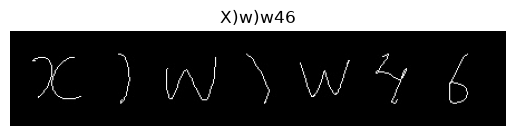

In [207]:
def render_sequence(sequence):
    images=[]
    for char in sequence:
        if char == ' ':
            images.append(np.zeros((img.shape[0], img.shape[1]), dtype=np.uint8))
            continue
        folder = char if char != '*' else 'times'
        folder = path_to_folder + '\\' + folder
        files = os.listdir(folder)
        img = cv2.imread(folder + '\\' + random.choice(files), cv2.IMREAD_GRAYSCALE)
        img = cv2.bitwise_not(img)
        if len(images) > 0:
            images.append(np.zeros((img.shape[0], 15), dtype=np.uint8))
        images.append(img)
    result = np.hstack(images)
    return cv2.copyMakeBorder(result, 20,20,20,20, cv2.BORDER_CONSTANT, value=0)

sequence = generate_sequence(chars)

demo = render_sequence(sequence)
plt.imshow(demo, cmap='gray'); plt.title(sequence);plt.axis('off')

        

Классификация

In [208]:
def load_dataset(max_for_class=10000):
    X, y =[], []
    for i, class_name in enumerate(name_folders):
        folder = path_to_folder + '\\' + class_name
        files = os.listdir(folder)
        files = files[:max_for_class]
        for file in files:
            img = cv2.imread(folder + '\\' + file, cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
            img = cv2.bitwise_not(img)
            img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE))
            X.append(img.flatten().astype(np.float32) / 255.0)
            y.append(i)
    return np.array(X), np.array(y)
    
X, y = load_dataset()
print("X:", X.shape, "y:", y.shape)

X: (127369, 2025) y: (127369,)


In [209]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, shuffle=True, stratify=y
)

k =  1 | точность = 0.9076
k =  2 | точность = 0.8058
k =  3 | точность = 0.7931
k =  5 | точность = 0.6654
k =  7 | точность = 0.6100
k =  9 | точность = 0.5697
k = 11 | точность = 0.5363
k = 15 | точность = 0.4868

Best k = 1, точность = 0.9362


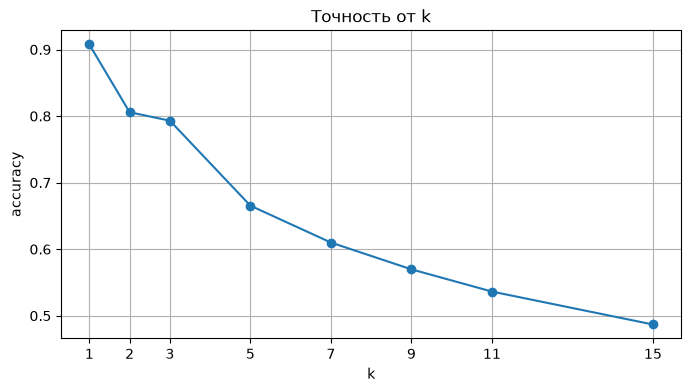

In [210]:
accs = []
for k in K_VALUES:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test))
    accs.append(acc)
    print(f"k = {k:2d} | точность = {acc:.4f}")

best_k = K_VALUES[int(np.argmax(accuracies))]
print(f"\nBest k = {best_k}, точность = {max(accuracies):.4f}")

plt.figure(figsize=(8, 4))
plt.plot(K_VALUES, accs, marker='o')
plt.xlabel('k'); plt.ylabel('accuracy')
plt.title('Точность от k')
plt.grid(True); plt.xticks(K_VALUES)
plt.show()

In [211]:
knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1).fit(X_train, y_train)
print(classification_report(y_test, knn.predict(X_test), target_names=name_folders, zero_division=0))

              precision    recall  f1-score   support

           (       0.85      0.98      0.91      3000
           )       0.84      0.99      0.91      3000
           +       0.98      0.69      0.81      3000
           ,       0.38      0.92      0.54       572
           -       0.83      1.00      0.91      3000
           0       1.00      0.97      0.98      2074
           1       0.79      0.84      0.81      3000
           2       0.97      0.71      0.82      3000
           3       0.98      0.96      0.97      3000
           4       0.99      0.96      0.98      2219
           5       0.98      0.94      0.96      1064
           6       1.00      0.95      0.97       936
           7       0.96      0.93      0.94       873
           8       1.00      0.95      0.97       920
           9       1.00      0.30      0.47       188
           X       0.99      0.88      0.93      3000
           h       1.00      0.99      0.99       439
           t       0.97    

Распознавание

In [212]:
def recognize(img_gray, classifier, class_names, img_size=IMAGE_SIZE):
    _, thresh = cv2.threshold(img_gray, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if w * h > 20:
            boxes.append([x, y, w, h])

    boxes.sort(key=lambda b: b[0])

    merged = []
    for box in boxes:
        if not merged:
            merged.append(box)
        else:
            px, py, pw, ph = merged[-1]
            x, y, w, h = box
            gap = x - (px + pw)
            if gap < 10:
                new_x = min(px, x)
                new_y = min(py, y)
                new_right = max(px + pw, x + w)
                new_bottom = max(py + ph, y + h)
                merged[-1] = [new_x, new_y, new_right - new_x, new_bottom - new_y]
            else:
                merged.append(box)

    boxes = [tuple(b) for b in merged]

    if not boxes:
        return '', []

    predicted_chars = []
    prev_right = None

    for (x, y, w, h) in boxes:
        if prev_right is not None:
            gap = x - prev_right
            if gap > 55:
                predicted_chars.append(' ')
        crop = img_gray[y:y+h, x:x+w]
        padded_crop = np.zeros((img_size, img_size), dtype=np.uint8)

        y_off = max(0, (img_size - h) // 2)
        x_off = max(0, (img_size - w) // 2)

        crop_h = min(h, img_size)
        crop_w = min(w, img_size)

        padded_crop[y_off:y_off+crop_h, x_off:x_off+crop_w] = crop[:crop_h, :crop_w]

        feat = padded_crop.astype(np.float32).flatten() / 255.0

        pred = classifier.predict([feat])[0]
        predicted_chars.append(class_names[int(pred)])
        prev_right = x + w

    return ''.join(predicted_chars), boxes

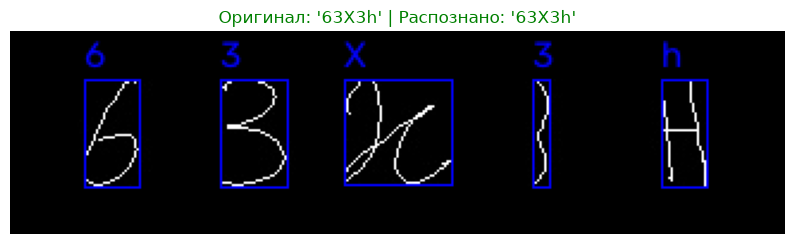

------------------------------------------------------------


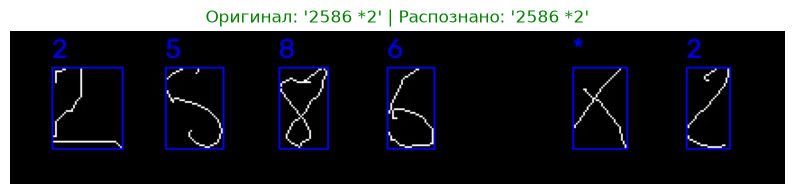

------------------------------------------------------------


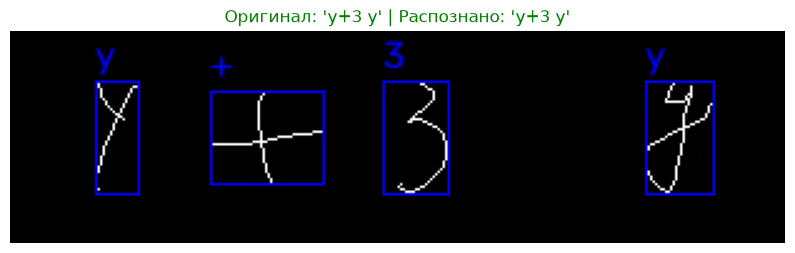

------------------------------------------------------------


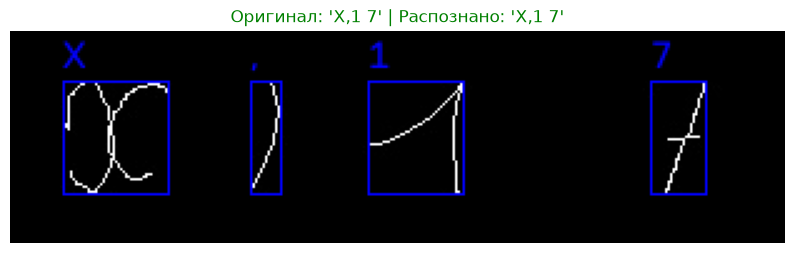

------------------------------------------------------------


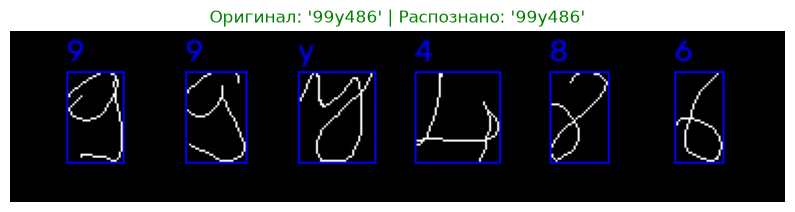

------------------------------------------------------------


In [214]:
num_tests = 5
for i in range(num_tests):
    true_seq = generate_sequence(chars)
    
    img = render_sequence(true_seq)
    
    rec_seq, boxes = recognize(img, knn, name_folders)
    
    rec_seq_pretty = rec_seq.replace('times', '*')
    
    true_clean = true_seq.strip()
    rec_clean = rec_seq_pretty.strip()
    
    vis_img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    
    for idx, (x, y, w, h) in enumerate(boxes):
        cv2.rectangle(vis_img, (x, y), (x + w, y + h), (0, 0, 255), 1)
        
        chars_only = rec_clean.replace(' ', '')
        if idx < len(chars_only):
            cv2.putText(vis_img, chars_only[idx], (x, max(y - 5, 10)), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

    plt.figure(figsize=(10, 3))
    plt.imshow(vis_img)
    plt.axis('off')
    
    title_color = 'green' if true_clean == rec_clean else 'red'
    plt.title(f"Оригинал: '{true_clean}' | Распознано: '{rec_clean}'", color=title_color, fontsize=12)
    plt.show()
    print("-" * 60)